Install Libraries

In [1]:
!pip install Optuna catboost
import os
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib
try:                                   # deteksi notebook
    get_ipython                        # noqa: F821
    IN_NB = True
except NameError:
    IN_NB = False
    matplotlib.use("Agg")              # mode skrip: simpan gambar tanpa jendela
import matplotlib.pyplot as plt
import optuna
from catboost import CatBoostClassifier, Pool
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, log_loss, brier_score_loss,
                             confusion_matrix, classification_report, roc_curve,
                             precision_recall_curve)
from sklearn.calibration import calibration_curve
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

optuna.logging.set_verbosity(optuna.logging.WARNING)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 442.4/442.4 kB 15.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 9.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.7/268.7 kB 24.4 MB/s eta 0:00:00


In [2]:
DATA_PATH = "WA_Fn-UseC_-Telco-Customer-Churn.csv"   # <- path dataset
OUT_DIR   = "output_churn_final"                     # <- folder hasil (gambar & CSV)
SEED      = 42
QUICK     = os.environ.get("QUICK", "0") == "1"      # True = versi kecil untuk uji kode
N_FOLDS   = 3 if QUICK else 5
N_TRIALS  = 3 if QUICK else 30       # percobaan Optuna
N_SEEDS   = 2 if QUICK else 3        # jumlah seed pada ensemble final
ITER_CAP  = 600 if QUICK else 2500   # batas iterasi (early stopping menentukan yang optimal)
RUN_SIZE_CURVE = not QUICK           # learning curve vs ukuran data (lebih lama)
DROP_WEAK = []                       # contoh: ["gender", "PhoneService"] jika ingin membuang fitur lemah
# Asumsi biaya bisnis untuk threshold berbasis biaya (GANTI dengan angka riil)
COST_FN = 500   # rugi bila pelanggan churn TIDAK terdeteksi
COST_FP = 50    # biaya kampanye retensi ke pelanggan yang sebenarnya tidak churn
# Batas segmen risiko berdasarkan probabilitas
RISK_BINS = [-0.01, 0.30, 0.60, 1.01]
# ---------------------------------------
os.makedirs(OUT_DIR, exist_ok=True)


def show(obj, title=None):
    """Tampilkan tabel: display() di notebook, print di terminal."""
    if title:
        print(f"\n{title}")
    if IN_NB:
        display(obj)                   # noqa: F821
    else:
        print(obj.to_string() if hasattr(obj, "to_string") else obj)


def savefig(name):
    plt.tight_layout()
    plt.savefig(f"{OUT_DIR}/{name}.png", dpi=150, bbox_inches="tight")
    if IN_NB:
        plt.show()
    plt.close()


Ukuran dataset: (7043, 21)

5 baris pertama:


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes



Missing value (NaN) per kolom: 0 total
Duplikat baris: 0 | duplikat customerID: 0
TotalCharges tidak valid: 11 | semuanya tenure=0: True

Data bersih: (7043, 19) | proporsi churn: 0.2654 (No 73.5% vs Yes 26.5%)


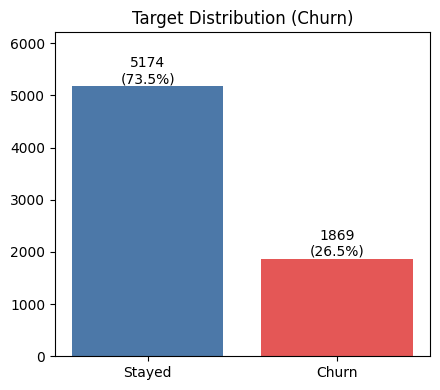

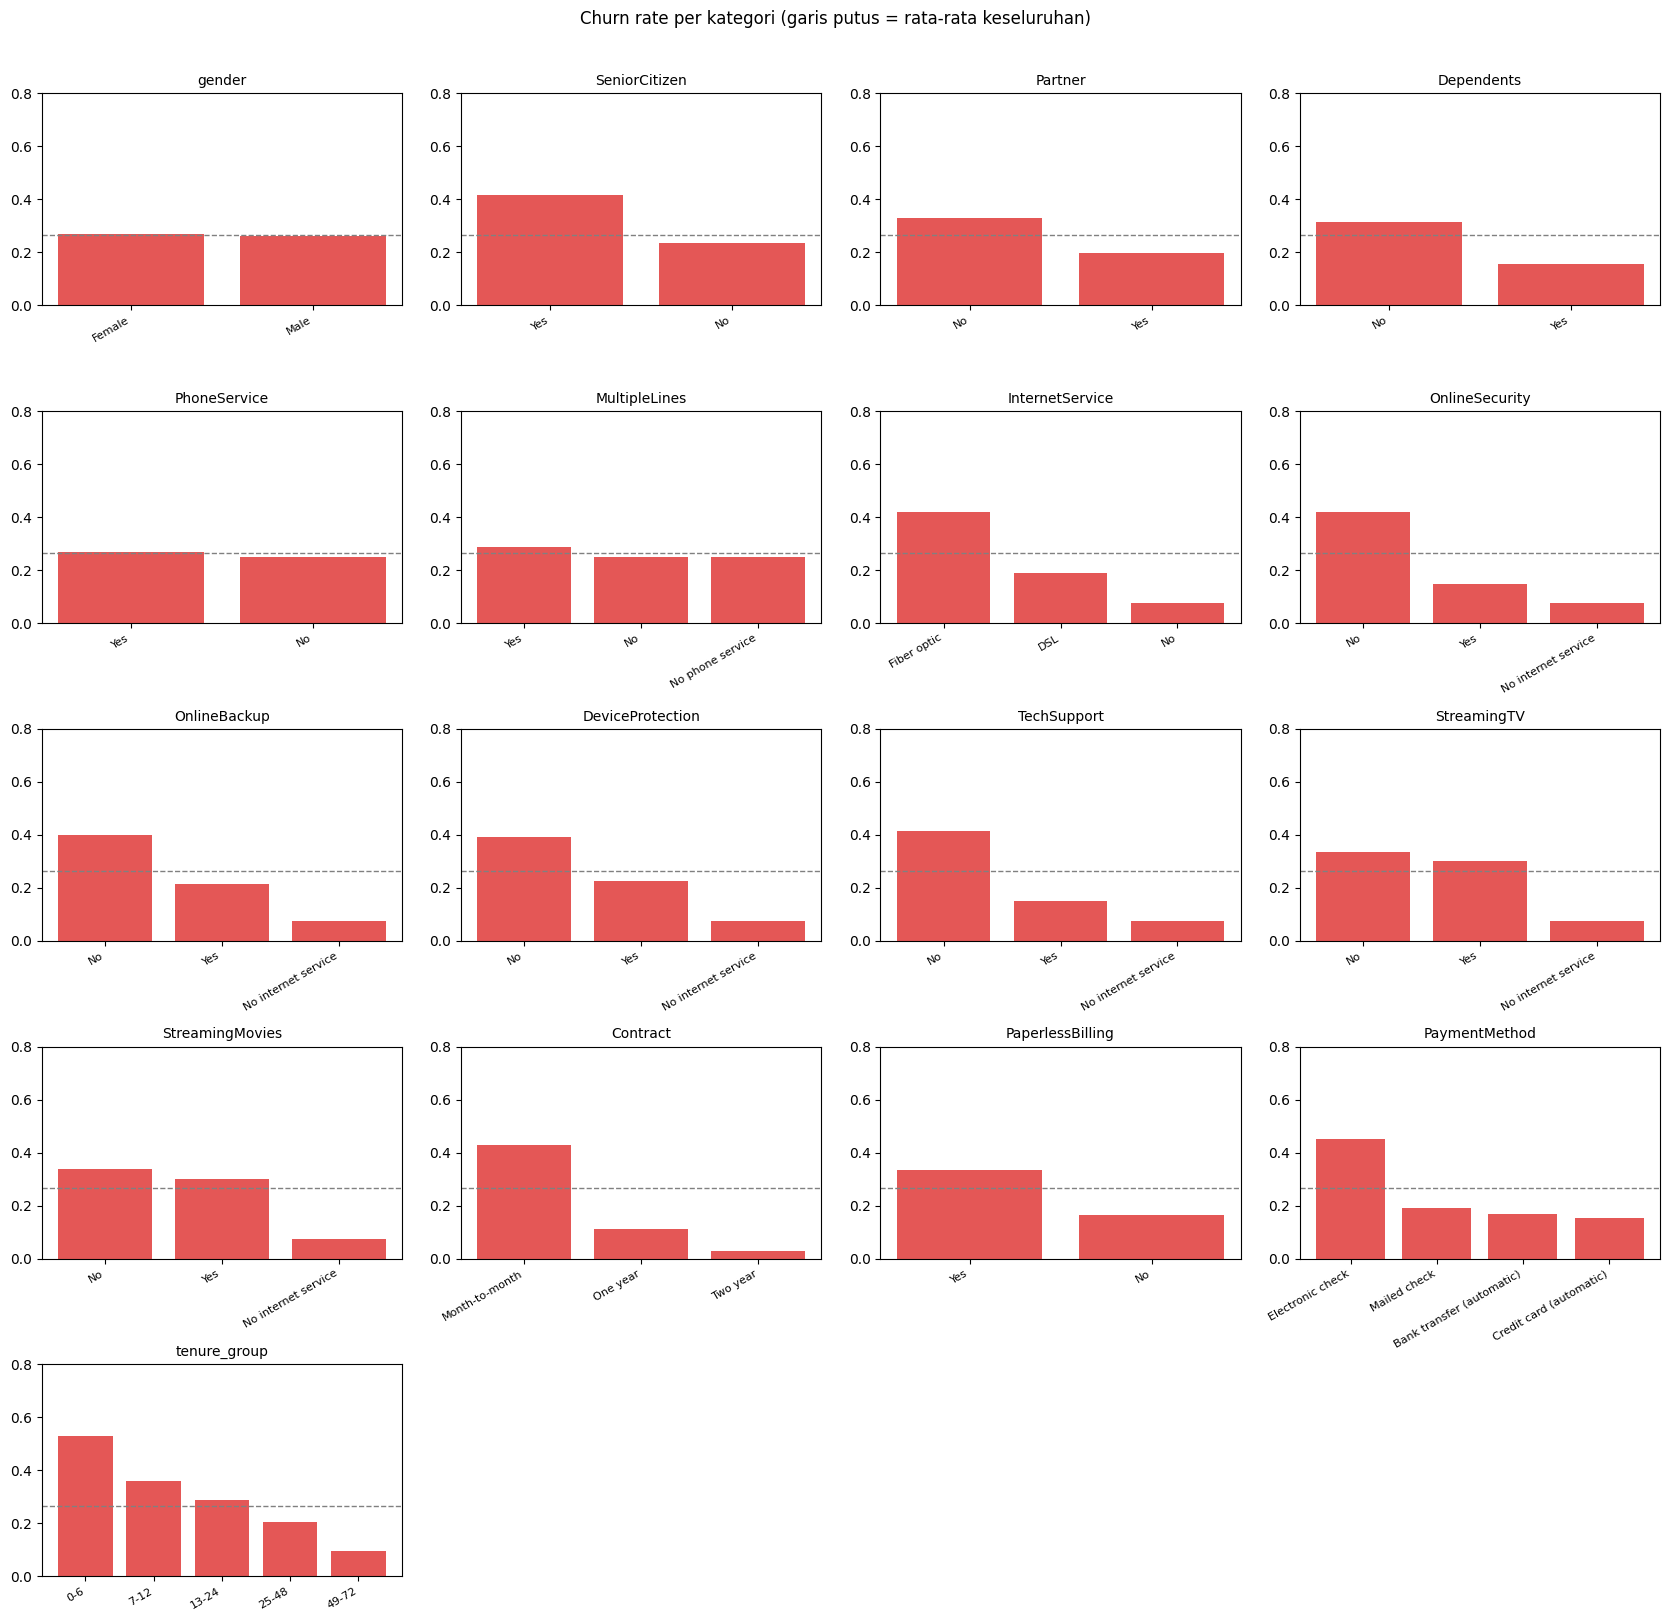

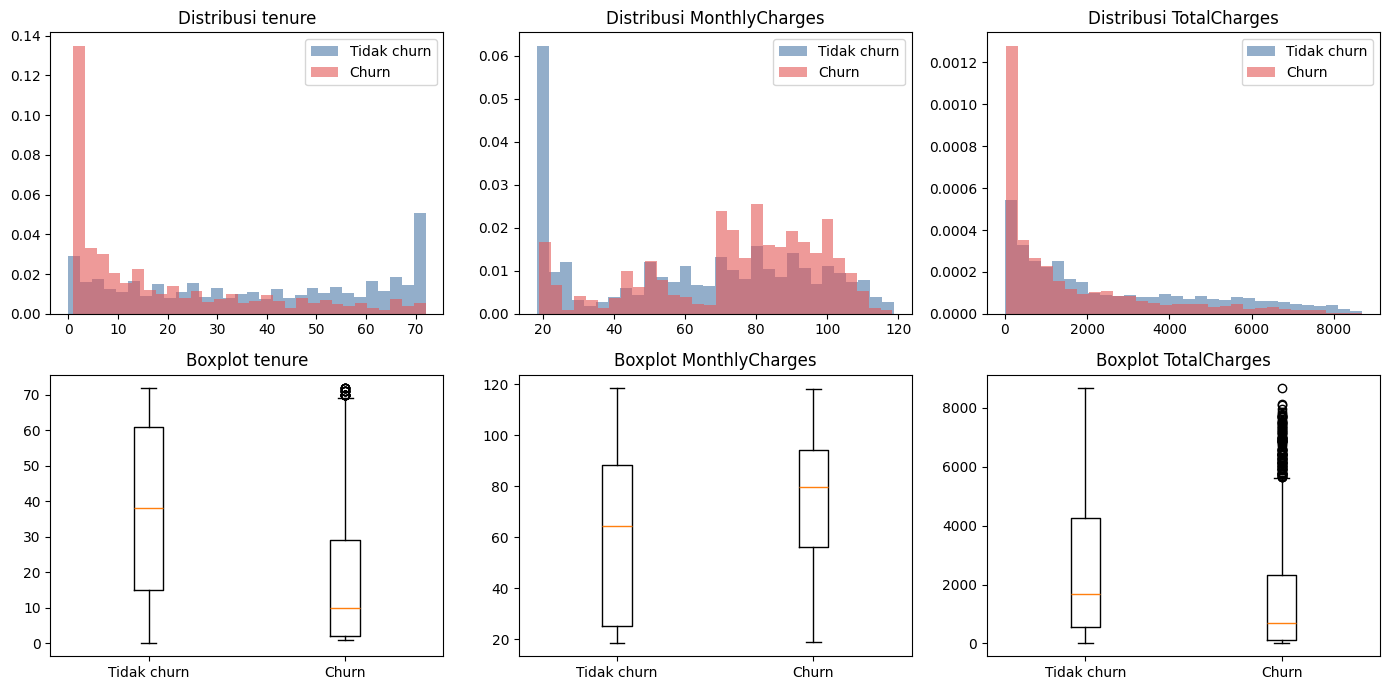

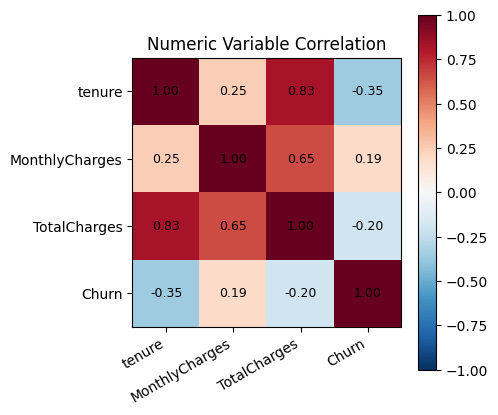


Profil rata-rata numerik: churner vs non-churner


,Tidak churn,Churn,Selisih (%)
tenure,37.57,17.98,-52.14
MonthlyCharges,61.27,74.44,21.51
TotalCharges,2549.91,1531.80,-39.93



12 features with HIGHEST churn rate


,Variabel,Kategori,Jumlah,Churn rate,Lift vs rata2
0,tenure_group,0-6,1481,0.529,1.995
1,PaymentMethod,Electronic check,2365,0.453,1.707
2,Contract,Month-to-month,3875,0.427,1.609
3,InternetService,Fiber optic,3096,0.419,1.579
4,OnlineSecurity,No,3498,0.418,1.574
5,SeniorCitizen,Yes,1142,0.417,1.571
6,TechSupport,No,3473,0.416,1.569
7,OnlineBackup,No,3088,0.399,1.505
8,DeviceProtection,No,3095,0.391,1.474
9,tenure_group,7-12,705,0.359,1.352



8 features with LOWEST churn rate


,Variabel,Kategori,Jumlah,Churn rate,Lift vs rata2
0,Dependents,Yes,2110,0.155,0.582
1,PaymentMethod,Credit card (automatic),1522,0.152,0.574
2,TechSupport,Yes,2044,0.152,0.572
3,OnlineSecurity,Yes,2019,0.146,0.551
4,Contract,One year,1473,0.113,0.425
5,tenure_group,49-72,2239,0.095,0.358
6,InternetService,No,1526,0.074,0.279
7,Contract,Two year,1695,0.028,0.107


In [3]:
df_raw = pd.read_csv(DATA_PATH)
print("Ukuran dataset:", df_raw.shape)
show(df_raw.head(), "5 baris pertama:")
print("\nMissing value (NaN) per kolom:", int(df_raw.isna().sum().sum()), "total")
print("Duplikat baris:", df_raw.duplicated().sum(), "| duplikat customerID:", df_raw["customerID"].duplicated().sum())

# TotalCharges bertipe string karena ada nilai " " -> semuanya pelanggan baru (tenure = 0)
tc_raw = pd.to_numeric(df_raw["TotalCharges"], errors="coerce")
print("TotalCharges tidak valid:", int(tc_raw.isna().sum()),
      "| semuanya tenure=0:", bool((df_raw.loc[tc_raw.isna(), "tenure"] == 0).all()))


def load_clean(raw):
    d = raw.copy()
    d["TotalCharges"] = pd.to_numeric(d["TotalCharges"], errors="coerce")
    d.loc[d["tenure"].eq(0), "TotalCharges"] = 0.0     # belum pernah ditagih -> 0 (bukan missing acak)
    d["TotalCharges"] = d["TotalCharges"].fillna(0.0)
    d["SeniorCitizen"] = d["SeniorCitizen"].map({0: "No", 1: "Yes"})   # samakan format dengan kolom lain
    y = d["Churn"].map({"No": 0, "Yes": 1}).astype(int)
    d = d.drop(columns=["Churn", "customerID"])
    return d, y


df_clean, y = load_clean(df_raw)
print(f"\nData bersih: {df_clean.shape} | proporsi churn: {y.mean():.4f} "
      f"(No {1 - y.mean():.1%} vs Yes {y.mean():.1%})")

# %% ===================== 2. EDA: KARAKTERISTIK PELANGGAN =====================
NUM_COLS_RAW = ["tenure", "MonthlyCharges", "TotalCharges"]
CAT_COLS_RAW = [c for c in df_clean.columns if c not in NUM_COLS_RAW]
eda = df_clean.copy()
eda["Churn"] = y
eda["tenure_group"] = pd.cut(eda["tenure"], [-1, 6, 12, 24, 48, 72],
                             labels=["0-6", "7-12", "13-24", "25-48", "49-72"]).astype(str)
base_rate = y.mean()

# 2a. Distribusi target
fig, ax = plt.subplots(figsize=(4.5, 4))
cnt = y.map({0: "Stayed", 1: "Churn"}).value_counts()
ax.bar(cnt.index, cnt.values, color=["#4C78A8", "#E45756"])
for i, v in enumerate(cnt.values):
    ax.text(i, v, f"{v}\n({v / len(y):.1%})", ha="center", va="bottom")
ax.set_title("Target Distribution (Churn)"); ax.set_ylim(0, cnt.max() * 1.2)
savefig("eda_01_target")

# 2b. Churn rate per variabel kategorikal
cat_plot = CAT_COLS_RAW + ["tenure_group"]
ncol = 4
nrow = int(np.ceil(len(cat_plot) / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(4.2 * ncol, 3.2 * nrow))
for ax, c in zip(axes.ravel(), cat_plot):
    r = eda.groupby(c)["Churn"].mean().sort_values(ascending=False)
    ax.bar(range(len(r)), r.values, color="#E45756")
    ax.axhline(base_rate, ls="--", c="gray", lw=1)
    ax.set_xticks(range(len(r))); ax.set_xticklabels(r.index, rotation=30, ha="right", fontsize=8)
    ax.set_title(c, fontsize=10); ax.set_ylim(0, 0.8)
for ax in axes.ravel()[len(cat_plot):]:
    ax.axis("off")
fig.suptitle("Churn rate per kategori (garis putus = rata-rata keseluruhan)", y=1.01)
savefig("eda_02_churn_rate_categorical")

# 2c. Distribusi variabel numerik: churn vs tidak churn
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for j, c in enumerate(NUM_COLS_RAW):
    for lab, col, nm in [(0, "#4C78A8", "Tidak churn"), (1, "#E45756", "Churn")]:
        axes[0, j].hist(eda.loc[eda["Churn"] == lab, c], bins=30, alpha=0.6, color=col,
                        density=True, label=nm)
    axes[0, j].set_title(f"Distribusi {c}"); axes[0, j].legend()
    axes[1, j].boxplot([eda.loc[eda["Churn"] == 0, c], eda.loc[eda["Churn"] == 1, c]],
                       labels=["Tidak churn", "Churn"])
    axes[1, j].set_title(f"Boxplot {c}")
savefig("eda_03_numeric_distribution")

# 2d. Korelasi numerik
corr = eda[NUM_COLS_RAW + ["Churn"]].corr()
fig, ax = plt.subplots(figsize=(5, 4.5))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr))); ax.set_xticklabels(corr.columns, rotation=30, ha="right")
ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=9)
plt.colorbar(im); ax.set_title("Numeric Variable Correlation")
savefig("eda_04_correlation")

# 2e. Profil churner vs non-churner
prof = eda.groupby("Churn")[NUM_COLS_RAW].mean().T
prof.columns = ["Tidak churn", "Churn"]
prof["Selisih (%)"] = (prof["Churn"] / prof["Tidak churn"] - 1) * 100
show(prof.round(2), "Profil rata-rata numerik: churner vs non-churner")

# 2f. Segmen pelanggan dengan churn rate tertinggi (dukungan minimal 100 pelanggan)
rows = []
for c in cat_plot:
    g = eda.groupby(c)["Churn"].agg(["mean", "count"])
    for val, r in g.iterrows():
        if r["count"] >= 100 and val not in ("No internet service", "No phone service"):
            rows.append({"Variabel": c, "Kategori": val, "Jumlah": int(r["count"]),
                         "Churn rate": r["mean"], "Lift vs rata2": r["mean"] / base_rate})
seg = pd.DataFrame(rows).sort_values("Churn rate", ascending=False)
show(seg.head(12).round(3).reset_index(drop=True), "12 features with HIGHEST churn rate")
show(seg.tail(8).round(3).reset_index(drop=True), "8 features with LOWEST churn rate")
seg.to_csv(f"{OUT_DIR}/segmen_churn_rate.csv", index=False)

In [4]:
# %% ===================== 3. FEATURE ENGINEERING =====================
def make_features(raw):
    d = raw.copy()
    svc = ["OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport",
           "StreamingTV", "StreamingMovies"]
    protect = ["OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport"]
    stream = ["StreamingTV", "StreamingMovies"]
    yes = lambda col: (d[col] == "Yes").astype(int)
    has_net = d["InternetService"] != "No"

    # jumlah layanan
    d["n_services"] = sum(yes(c) for c in svc)
    d["n_protect"] = sum(yes(c) for c in protect)
    d["n_stream"] = sum(yes(c) for c in stream)
    d["n_services_total"] = d["n_services"] + yes("PhoneService") + yes("MultipleLines")
    d["has_internet"] = has_net.astype(int)
    d["no_protection"] = (has_net & (d["n_protect"] == 0)).astype(int)

    # perilaku tagihan
    d["avg_charge"] = d["TotalCharges"] / d["tenure"].clip(lower=1)
    d["charge_diff"] = d["MonthlyCharges"] - d["avg_charge"]
    d["charge_ratio"] = d["MonthlyCharges"] / (d["avg_charge"].abs() + 1e-6)
    d["total_gap"] = d["TotalCharges"] - d["MonthlyCharges"] * d["tenure"]
    d["charge_per_service"] = d["MonthlyCharges"] / (d["n_services_total"] + 1)
    d["log_total"] = np.log1p(d["TotalCharges"].clip(lower=0))
    peer = d.groupby("InternetService")["MonthlyCharges"].transform("median")
    d["price_vs_peer"] = d["MonthlyCharges"] / peer

    # fase hidup pelanggan
    d["tenure_group"] = pd.cut(d["tenure"], [-1, 6, 12, 24, 48, 72],
                               labels=["0-6", "7-12", "13-24", "25-48", "49-72"]).astype(str)
    d["is_new"] = (d["tenure"] <= 6).astype(int)
    d["contract_months"] = d["Contract"].map({"Month-to-month": 1, "One year": 12, "Two year": 24})
    d["tenure_over_contract"] = d["tenure"] / d["contract_months"]

    # profil risiko (berdasarkan temuan EDA)
    d["auto_pay"] = d["PaymentMethod"].str.contains("automatic").astype(int)
    d["family"] = ((d["Partner"] == "Yes") | (d["Dependents"] == "Yes")).astype(int)
    d["net_no_support"] = (has_net & (d["TechSupport"] == "No") & (d["OnlineSecurity"] == "No")).astype(int)
    d["fiber_no_support"] = ((d["InternetService"] == "Fiber optic") & (d["TechSupport"] == "No")).astype(int)
    d["mtm_echeck"] = ((d["Contract"] == "Month-to-month") &
                       (d["PaymentMethod"] == "Electronic check")).astype(int)
    d["risk_flags"] = d[["net_no_support", "fiber_no_support", "mtm_echeck", "is_new"]].sum(axis=1)

    # interaksi kategorikal
    d["contract_x_net"] = d["Contract"] + "|" + d["InternetService"]
    d["contract_x_pay"] = d["Contract"] + "|" + d["PaymentMethod"]

    return d.drop(columns=[c for c in DROP_WEAK if c in d.columns])


X_all = make_features(df_clean)
CAT_COLS = X_all.select_dtypes(include=["object", "string"]).columns.tolist()
for c in CAT_COLS:
    X_all[c] = X_all[c].astype(str)
assert not X_all.isna().any().any(), "Masih ada NaN setelah feature engineering"
print(f"Jumlah fitur: {X_all.shape[1]} | kategorikal native CatBoost: {len(CAT_COLS)}")

Jumlah fitur: 44 | kategorikal native CatBoost: 19


In [5]:
# %% ===================== 4. SPLIT DATA =====================
# Test set dikunci: HANYA dipakai untuk evaluasi akhir (tidak untuk tuning, threshold, maupun kurva diagnostik).
X_dev, X_test, y_dev, y_test = train_test_split(X_all, y, test_size=0.20, random_state=SEED, stratify=y)
X_dev, X_test = X_dev.reset_index(drop=True), X_test.reset_index(drop=True)
y_dev, y_test = y_dev.reset_index(drop=True), y_test.reset_index(drop=True)
print("Development:", X_dev.shape, "| Test:", X_test.shape,
      f"| churn dev {y_dev.mean():.3f} / test {y_test.mean():.3f}")

Development: (5634, 44) | Test: (1409, 44) | churn dev 0.265 / test 0.265


Baseline Logistic Regression

In [6]:
num_feats = [c for c in X_all.columns if c not in CAT_COLS]
baseline = make_pipeline(
    ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore"), CAT_COLS),
                       ("num", StandardScaler(), num_feats)]),
    LogisticRegression(max_iter=3000, C=0.5))
skf_main = StratifiedKFold(N_FOLDS, shuffle=True, random_state=SEED)
base_oof = np.zeros(len(X_dev))
for tr, va in skf_main.split(X_dev, y_dev):
    baseline.fit(X_dev.iloc[tr], y_dev.iloc[tr])
    base_oof[va] = baseline.predict_proba(X_dev.iloc[va])[:, 1]
baseline.fit(X_dev, y_dev)
p_test_base = baseline.predict_proba(X_test)[:, 1]
print(f"[Baseline LogReg] CV AUC (OOF dev) = {roc_auc_score(y_dev, base_oof):.4f} | "
      f"Test AUC = {roc_auc_score(y_test, p_test_base):.4f} | Test PR-AUC = {average_precision_score(y_test, p_test_base):.4f}")

[Baseline LogReg] CV AUC (OOF dev) = 0.8480 | Test AUC = 0.8485 | Test PR-AUC = 0.6667


In [7]:
# %% ===================== 6. CATBOOST: KONFIGURASI & CROSS-VALIDATION =====================
# auto_class_weights=None: imbalance (26,5%) ditangani lewat threshold + PR-AUC, sehingga probabilitas tetap "jujur".
BASE_PARAMS = dict(iterations=ITER_CAP, loss_function="Logloss", eval_metric="AUC",
                   allow_writing_files=False, verbose=False, thread_count=-1,
                   auto_class_weights=None)


def make_pool(X, label=None):
    return Pool(X, label=label, cat_features=[c for c in CAT_COLS if c in X.columns])


def cv_evaluate(params, X, yv, n_splits=N_FOLDS):
    skf = StratifiedKFold(n_splits, shuffle=True, random_state=SEED)
    r = {k: [] for k in ["auc_va", "auc_tr", "acc_va", "acc_tr", "ll_va", "ll_tr", "iters"]}
    oof = np.zeros(len(X))
    for fold, (tr, va) in enumerate(skf.split(X, yv), 1):
        m = CatBoostClassifier(**BASE_PARAMS, **params, random_seed=SEED + fold, early_stopping_rounds=100)
        m.fit(make_pool(X.iloc[tr], yv.iloc[tr]), eval_set=make_pool(X.iloc[va], yv.iloc[va]),
              use_best_model=True)
        p_va = m.predict_proba(make_pool(X.iloc[va]))[:, 1]
        p_tr = m.predict_proba(make_pool(X.iloc[tr]))[:, 1]
        oof[va] = p_va
        r["auc_va"].append(roc_auc_score(yv.iloc[va], p_va)); r["auc_tr"].append(roc_auc_score(yv.iloc[tr], p_tr))
        r["acc_va"].append(accuracy_score(yv.iloc[va], p_va >= 0.5)); r["acc_tr"].append(accuracy_score(yv.iloc[tr], p_tr >= 0.5))
        r["ll_va"].append(log_loss(yv.iloc[va], p_va)); r["ll_tr"].append(log_loss(yv.iloc[tr], p_tr))
        r["iters"].append(m.get_best_iteration() + 1)
    mean = {k: float(np.mean(v)) for k, v in r.items()}
    return {"oof": oof,
            "CV_AUC": mean["auc_va"], "CV_AUC_SD": float(np.std(r["auc_va"])),
            "Train_AUC": mean["auc_tr"], "Gap_AUC": mean["auc_tr"] - mean["auc_va"],
            "Train_Acc": mean["acc_tr"], "Val_Acc": mean["acc_va"], "Gap_Acc": mean["acc_tr"] - mean["acc_va"],
            "Train_LogLoss": mean["ll_tr"], "Val_LogLoss": mean["ll_va"], "Gap_LogLoss": mean["ll_va"] - mean["ll_tr"],
            "Best_Iterations": int(np.median(r["iters"]))}

In [8]:
# %% ===================== 7. TUNING OPTUNA DENGAN REGULARISASI =====================
def objective(trial):
    params = {
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.05, log=True),
        "depth": trial.suggest_int("depth", 3, 5),
        "l2_leaf_reg": trial.suggest_float("l2_leaf_reg", 8.0, 40.0, log=True),
        "random_strength": trial.suggest_float("random_strength", 1.0, 8.0, log=True),
        "bootstrap_type": "Bayesian",
        "bagging_temperature": trial.suggest_float("bagging_temperature", 1.0, 8.0),
    }
    res = cv_evaluate(params, X_dev, y_dev, n_splits=3)
    # Skor = AUC validasi dikurangi penalti ringan untuk gap train-val yang positif
    score = (res["CV_AUC"] - 0.20 * max(res["Gap_AUC"], 0) - 0.05 * max(res["Gap_Acc"], 0)
             - 0.02 * max(res["Gap_LogLoss"], 0))
    for k in ["CV_AUC", "Gap_AUC", "Gap_Acc", "Gap_LogLoss"]:
        trial.set_user_attr(k, float(res[k]))
    return score


study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEED + 100))
study.optimize(objective, n_trials=N_TRIALS, show_progress_bar=False)
FINAL_PARAMS = {**study.best_params, "bootstrap_type": "Bayesian"}
print("Parameter terbaik:", FINAL_PARAMS)
print("Skor objective (dengan penalti gap):", round(study.best_value, 5))

Parameter terbaik: {'learning_rate': 0.012780495400563486, 'depth': 3, 'l2_leaf_reg': 28.854496917557526, 'random_strength': 4.483859889803099, 'bagging_temperature': 2.7576445454975675, 'bootstrap_type': 'Bayesian'}
Skor objective (dengan penalti gap): 0.8457


In [ ]:
# %% ===================== 8. VALIDASI CV MODEL FINAL & DIAGNOSIS OVERFITTING =====================
res_final = cv_evaluate(FINAL_PARAMS, X_dev, y_dev)
cv_table = pd.Series({k: v for k, v in res_final.items() if k != "oof"}, name="Model final")
show(cv_table.to_frame().round(4), f"Hasil CV {N_FOLDS}-fold (data development)")
FINAL_ITERATIONS = max(100, res_final["Best_Iterations"])
print("Jumlah iterasi model final:", FINAL_ITERATIONS)

g = res_final["Gap_AUC"]
verdict = ("gap kecil (overfitting minimal)" if g < 0.02 else
           "overfitting ringan / terkendali" if g < 0.05 else "overfitting nyata -> perkuat regularisasi")
print(f"Diagnosis: gap AUC train-val = {g:.4f} -> {verdict}")


Hasil CV 5-fold (data development)


,Model final
CV_AUC,0.8487
CV_AUC_SD,0.0122
Train_AUC,0.8582
Gap_AUC,0.0095
Train_Acc,0.8102
Val_Acc,0.8028
Gap_Acc,0.0074
Train_LogLoss,0.4023
Val_LogLoss,0.4142
Gap_LogLoss,0.0119


Jumlah iterasi model final: 1066
Diagnosis: gap AUC train-val = 0.0095 -> gap kecil (overfitting minimal)


In [ ]:
# %% ===================== 9. MODEL FINAL (ENSEMBLE SEED) =====================
model_params = {**BASE_PARAMS, **FINAL_PARAMS}
model_params.pop("iterations", None)
final_models = []
for s in range(N_SEEDS):
    m = CatBoostClassifier(**model_params, iterations=FINAL_ITERATIONS, random_seed=SEED + s)
    m.fit(make_pool(X_dev, y_dev))
    final_models.append(m)


def ensemble_proba(X):
    pool = make_pool(X)
    return np.mean([m.predict_proba(pool)[:, 1] for m in final_models], axis=0)


p_dev, p_test = ensemble_proba(X_dev), ensemble_proba(X_test)


def report_metrics(label, yy, pp, thr=0.35):
    pred = (pp >= thr).astype(int)
    return {"Set": label, "Threshold": round(float(thr), 2),
            "Accuracy": accuracy_score(yy, pred), "Precision": precision_score(yy, pred, zero_division=0),
            "Recall": recall_score(yy, pred, zero_division=0), "F1": f1_score(yy, pred, zero_division=0),
            "ROC_AUC": roc_auc_score(yy, pp), "PR_AUC": average_precision_score(yy, pp),
            "LogLoss": log_loss(yy, pp), "Brier": brier_score_loss(yy, pp)}


show(pd.DataFrame([report_metrics("Development (in-sample)", y_dev, p_dev),
                   report_metrics("Test (final)", y_test, p_test)]).set_index("Set").round(4),
     "Metrik model final (threshold 0.50)")
print("Gap AUC dev-test:", round(roc_auc_score(y_dev, p_dev) - roc_auc_score(y_test, p_test), 4))


Metrik model final (threshold 0.50)


,Threshold,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC,LogLoss,Brier
Set,,,,,,,,,
Development (in-sample),0.35,0.7952,0.5948,0.7157,0.6497,0.8579,0.6865,0.4022,0.1296
Test (final),0.35,0.7821,0.5711,0.7193,0.6367,0.8465,0.6661,0.4142,0.1351


Gap AUC dev-test: 0.0114


Threshold dari OOF

In [ ]:
oof = res_final["oof"]
grid = np.arange(0.05, 0.80, 0.01)
THR_F1 = float(grid[np.argmax([f1_score(y_dev, oof >= t) for t in grid])])
cost_fn = lambda yt, p, t: (((p < t) & (yt == 1)).sum() * COST_FN + ((p >= t) & (yt == 0)).sum() * COST_FP)
THR_COST = float(grid[np.argmin([cost_fn(y_dev.values, oof, t) for t in grid])])

thr_rows = []
for nm, t in [("Default 0.50", 0.5), ("F1-optimal (OOF)", THR_F1), ("Biaya-optimal (OOF)", THR_COST)]:
    d = report_metrics(nm, y_test, p_test, t)
    d["Biaya total (test)"] = int(cost_fn(y_test.values, p_test, t))
    thr_rows.append(d)
thr_df = pd.DataFrame(thr_rows).set_index("Set")[["Threshold", "Accuracy", "Precision", "Recall", "F1", "Biaya total (test)"]]
show(thr_df.round(4), "Perbandingan threshold pada TEST set")
print("Biaya tanpa model (tidak ada intervensi):", int(y_test.sum() * COST_FN))
THR_FINAL = THR_F1   # <- pilih threshold operasional di sini (THR_F1 / THR_COST / 0.5)
pred_test = (p_test >= THR_FINAL).astype(int)
print(f"\nThreshold operasional = {THR_FINAL:.2f}")
print("Confusion matrix [[TN FP],[FN TP]]:\n", confusion_matrix(y_test, pred_test))
print(classification_report(y_test, pred_test, target_names=["No churn", "Churn"], digits=3))


Perbandingan threshold pada TEST set


,Threshold,Accuracy,Precision,Recall,F1,Biaya total (test)
Set,,,,,,
Default 0.50,0.50,0.8027,0.6600,0.5294,0.5875,93100
F1-optimal (OOF),0.35,0.7821,0.5711,0.7193,0.6367,62600
Biaya-optimal (OOF),0.09,0.5905,0.3903,0.9652,0.5558,34700


Biaya tanpa model (tidak ada intervensi): 187000

Threshold operasional = 0.35
Confusion matrix [[TN FP],[FN TP]]:
 [[833 202]
 [105 269]]
              precision    recall  f1-score   support

    No churn      0.888     0.805     0.844      1035
       Churn      0.571     0.719     0.637       374

    accuracy                          0.782      1409
   macro avg      0.730     0.762     0.741      1409
weighted avg      0.804     0.782     0.789      1409



Comparison

In [ ]:
# ===== PERBANDINGAN CatBoost vs Logistic Regression =====
cb_oof = res_final["oof"]

# 1. Tabel test set: metrik sama, threshold dipilih dari OOF masing-masing model
def best_thr(oof_p):
    f1s   = [f1_score(y_dev, oof_p >= t) for t in grid]
    costs = [cost_fn(y_dev.values, oof_p, t) for t in grid]
    return float(grid[int(np.argmax(f1s))]), float(grid[int(np.argmin(costs))])

models = {"LogReg (baseline)": (base_oof, p_test_base), "CatBoost": (cb_oof, p_test)}
rows = []
for name, (o, p) in models.items():
    t_f1, t_cost = best_thr(o)
    for lab, t in [("thr 0.50", 0.5), ("F1-opt (OOF)", t_f1), ("Cost-opt (OOF)", t_cost)]:
        d = report_metrics(f"{name} | {lab}", y_test, p, t)
        d["Biaya total (test)"] = int(cost_fn(y_test.values, p, t))
        rows.append(d)
cmp_df = pd.DataFrame(rows).set_index("Set")[["Threshold", "Accuracy", "Precision", "Recall", "F1",
                                              "ROC_AUC", "PR_AUC", "LogLoss", "Brier", "Biaya total (test)"]]
show(cmp_df.round(4), "CatBoost vs LogReg pada TEST set")
print("Biaya tanpa model:", int(y_test.sum() * COST_FN))
cmp_df.to_csv(f"{OUT_DIR}/compare_catboost_vs_logreg.csv")

# 2. AUC per fold (fold sama persis dengan CV CatBoost)
folds = list(skf_main.split(X_dev, y_dev))
fold_auc = pd.DataFrame({
    "LogReg":   [roc_auc_score(y_dev.iloc[va], base_oof[va]) for _, va in folds],
    "CatBoost": [roc_auc_score(y_dev.iloc[va], cb_oof[va])   for _, va in folds]},
    index=[f"Fold {i}" for i in range(1, len(folds) + 1)])
fold_auc.loc["Mean"] = fold_auc.mean()
fold_auc.loc["SD"] = fold_auc.iloc[:len(folds)].std(ddof=0)
show(fold_auc.round(4), "AUC per fold (CV, data dev)")

# 3. Uji selisih: paired bootstrap pada test set
rng, yt = np.random.default_rng(SEED), y_test.values
d_auc, d_ap = [], []
for _ in range(2000):
    i = rng.integers(0, len(yt), len(yt))
    if yt[i].min() == yt[i].max():
        continue
    d_auc.append(roc_auc_score(yt[i], p_test[i]) - roc_auc_score(yt[i], p_test_base[i]))
    d_ap.append(average_precision_score(yt[i], p_test[i]) - average_precision_score(yt[i], p_test_base[i]))
for nm, dd in [("ROC-AUC", d_auc), ("PR-AUC", d_ap)]:
    lo, hi = np.percentile(dd, [2.5, 97.5])
    print(f"Selisih {nm} (CatBoost - LogReg): mean {np.mean(dd):+.4f} | 95% CI [{lo:+.4f}, {hi:+.4f}] ->",
          "signifikan" if (lo > 0 or hi < 0) else "CI mencakup 0, belum bisa disimpulkan")


CatBoost vs LogReg pada TEST set


,Threshold,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC,LogLoss,Brier,Biaya total (test)
Set,,,,,,,,,,
LogReg (baseline) | thr 0.50,0.50,0.8077,0.6746,0.5321,0.5949,0.8485,0.6667,0.4117,0.1341,92300
LogReg (baseline) | F1-opt (OOF),0.35,0.7757,0.5607,0.7166,0.6291,0.8485,0.6667,0.4117,0.1341,63500
LogReg (baseline) | Cost-opt (OOF),0.08,0.5827,0.3854,0.9626,0.5505,0.8485,0.6667,0.4117,0.1341,35700
CatBoost | thr 0.50,0.50,0.8027,0.6600,0.5294,0.5875,0.8465,0.6661,0.4142,0.1351,93100
CatBoost | F1-opt (OOF),0.35,0.7821,0.5711,0.7193,0.6367,0.8465,0.6661,0.4142,0.1351,62600
CatBoost | Cost-opt (OOF),0.09,0.5905,0.3903,0.9652,0.5558,0.8465,0.6661,0.4142,0.1351,34700


Biaya tanpa model: 187000

AUC per fold (CV, data dev)


,LogReg,CatBoost
Fold 1,0.8442,0.8408
Fold 2,0.8275,0.8312
Fold 3,0.8444,0.8475
Fold 4,0.8631,0.8648
Fold 5,0.8636,0.8592
Mean,0.8486,0.8487
SD,0.0135,0.0122


Selisih ROC-AUC (CatBoost - LogReg): mean -0.0018 | 95% CI [-0.0067, +0.0030] -> CI mencakup 0, belum bisa disimpulkan
Selisih PR-AUC (CatBoost - LogReg): mean -0.0006 | 95% CI [-0.0120, +0.0108] -> CI mencakup 0, belum bisa disimpulkan


Evaluasi

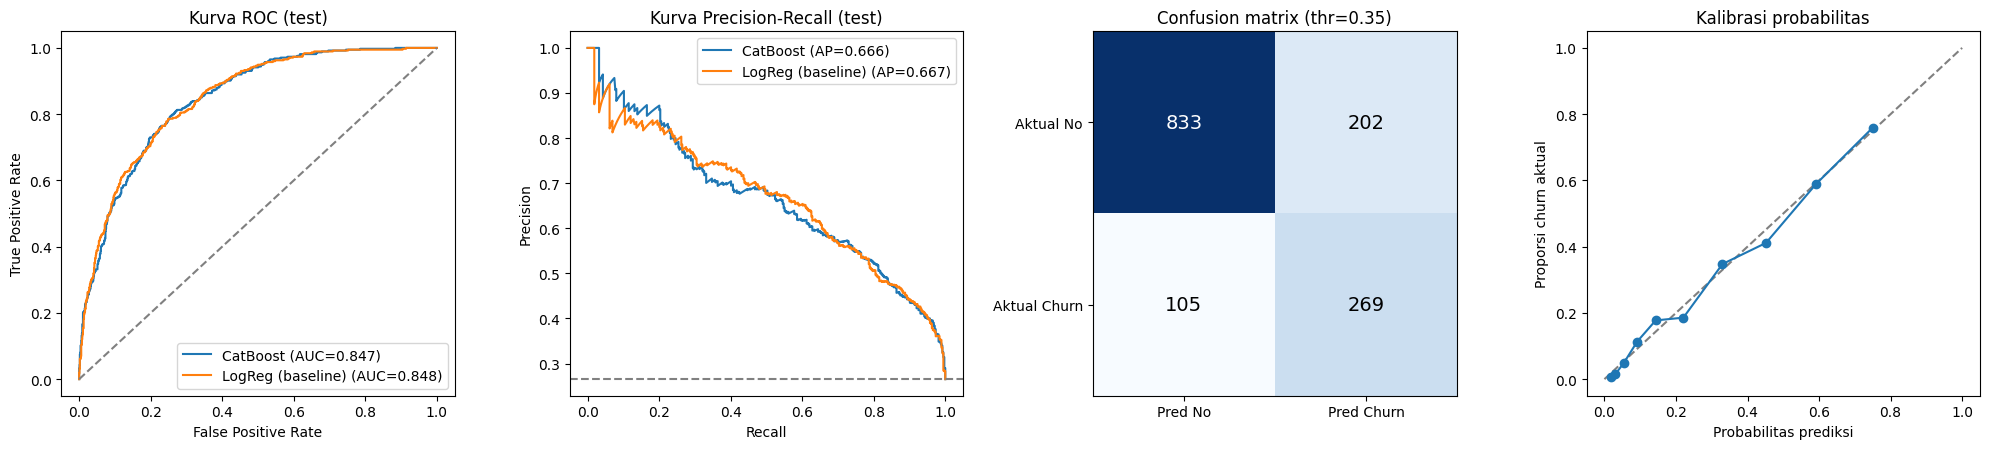

In [ ]:
# %% ===================== 11. VISUALISASI EVALUASI (ROC, PR, CONFUSION, KALIBRASI) =====================
fig, ax = plt.subplots(1, 4, figsize=(20, 4.6))
for p, nm in [(p_test, "CatBoost"), (p_test_base, "LogReg (baseline)")]:
    fpr, tpr, _ = roc_curve(y_test, p)
    ax[0].plot(fpr, tpr, label=f"{nm} (AUC={roc_auc_score(y_test, p):.3f})")
    pr, rc, _ = precision_recall_curve(y_test, p)
    ax[1].plot(rc, pr, label=f"{nm} (AP={average_precision_score(y_test, p):.3f})")
ax[0].plot([0, 1], [0, 1], "--", c="gray"); ax[0].set_title("Kurva ROC (test)")
ax[0].set_xlabel("False Positive Rate"); ax[0].set_ylabel("True Positive Rate"); ax[0].legend()
ax[1].axhline(y_test.mean(), ls="--", c="gray"); ax[1].set_title("Kurva Precision-Recall (test)")
ax[1].set_xlabel("Recall"); ax[1].set_ylabel("Precision"); ax[1].legend()
cm = confusion_matrix(y_test, pred_test)
ax[2].imshow(cm, cmap="Blues")
for i in range(2):
    for j in range(2):
        ax[2].text(j, i, cm[i, j], ha="center", va="center", fontsize=14,
                   color="white" if cm[i, j] > cm.max() / 2 else "black")
ax[2].set_xticks([0, 1]); ax[2].set_xticklabels(["Pred No", "Pred Churn"])
ax[2].set_yticks([0, 1]); ax[2].set_yticklabels(["Aktual No", "Aktual Churn"])
ax[2].set_title(f"Confusion matrix (thr={THR_FINAL:.2f})")
fp_, mp_ = calibration_curve(y_test, p_test, n_bins=10, strategy="quantile")
ax[3].plot([0, 1], [0, 1], "--", c="gray"); ax[3].plot(mp_, fp_, "o-")
ax[3].set_title("Kalibrasi probabilitas"); ax[3].set_xlabel("Probabilitas prediksi"); ax[3].set_ylabel("Proporsi churn aktual")
savefig("eval_01_roc_pr_cm_calibration")

In [ ]:
# %% ===================== 12. LEARNING CURVE (TRAIN vs VALIDATION, BUKAN TEST) =====================
# Revisi: kurva memakai validation set yang dipisah dari DEV, sehingga test set tetap murni.
X_tr, X_val, y_tr, y_val = train_test_split(X_dev, y_dev, test_size=0.20, random_state=SEED, stratify=y_dev)
lc_params = {**model_params, "eval_metric": "Logloss"}
m_lc = CatBoostClassifier(**lc_params, iterations=FINAL_ITERATIONS * 2, random_seed=SEED)
m_lc.fit(make_pool(X_tr, y_tr), eval_set=make_pool(X_val, y_val), use_best_model=False)
ev = m_lc.get_evals_result()
tr_ll, va_ll = ev["learn"]["Logloss"], ev["validation"]["Logloss"]
best_it = int(np.argmin(va_ll))
PERIOD = 10   # AUC per iterasi dihitung manual (CatBoost tidak mencatat AUC train secara otomatis)
tr_auc = [roc_auc_score(y_tr, p[:, 1]) for p in m_lc.staged_predict_proba(make_pool(X_tr), eval_period=PERIOD)]
va_auc = [roc_auc_score(y_val, p[:, 1]) for p in m_lc.staged_predict_proba(make_pool(X_val), eval_period=PERIOD)]
x_auc = np.arange(1, len(tr_auc) + 1) * PERIOD
print(f"Iterasi terbaik (logloss validasi minimum) = {best_it + 1} | iterasi model final = {FINAL_ITERATIONS}")

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].plot(tr_ll, label="Train", lw=2); ax[0].plot(va_ll, label="Validation", lw=2)
ax[0].axvline(best_it, ls="--", c="gray", label=f"Best iter = {best_it + 1}")
ax[0].set_title("Learning curve - Logloss"); ax[0].set_xlabel("Iterasi"); ax[0].set_ylabel("Logloss"); ax[0].legend()
ax[1].plot(x_auc, tr_auc, label="Train", lw=2); ax[1].plot(x_auc, va_auc, label="Validation", lw=2)
ax[1].axvline(best_it + 1, ls="--", c="gray", label=f"Best iter = {best_it + 1}")
ax[1].set_title("Learning curve - ROC-AUC"); ax[1].set_xlabel("Iterasi"); ax[1].set_ylabel("AUC"); ax[1].legend()
savefig("overfit_01_learning_curve_iterations")

if RUN_SIZE_CURVE:   # learning curve terhadap ukuran data (CV di data dev)
    fracs, rows = [0.2, 0.4, 0.6, 0.8, 1.0], []
    skf3 = StratifiedKFold(3, shuffle=True, random_state=SEED)
    for f in fracs:
        a_tr, a_va = [], []
        for tr, va in skf3.split(X_dev, y_dev):
            sub = tr if f == 1.0 else np.random.RandomState(SEED).choice(tr, int(len(tr) * f), replace=False)
            mm = CatBoostClassifier(**model_params, iterations=FINAL_ITERATIONS, random_seed=SEED)
            mm.fit(make_pool(X_dev.iloc[sub], y_dev.iloc[sub]))
            a_tr.append(roc_auc_score(y_dev.iloc[sub], mm.predict_proba(make_pool(X_dev.iloc[sub]))[:, 1]))
            a_va.append(roc_auc_score(y_dev.iloc[va], mm.predict_proba(make_pool(X_dev.iloc[va]))[:, 1]))
        rows.append({"n_train": int(len(X_dev) * 2 / 3 * f), "train_auc": np.mean(a_tr), "cv_auc": np.mean(a_va)})
    lc_size = pd.DataFrame(rows); lc_size["gap"] = lc_size["train_auc"] - lc_size["cv_auc"]
    show(lc_size.round(4), "Learning curve vs ukuran data")
    plt.figure(figsize=(6, 4.5))
    plt.plot(lc_size["n_train"], lc_size["train_auc"], "o-", label="Train")
    plt.plot(lc_size["n_train"], lc_size["cv_auc"], "o-", label="CV (validation)")
    plt.xlabel("Jumlah data latih"); plt.ylabel("ROC-AUC"); plt.title("Learning curve vs ukuran data"); plt.legend()
    savefig("overfit_02_learning_curve_size")

In [ ]:
# %% ===================== 13. INTERPRETASI MODEL: FEATURE IMPORTANCE =====================
imp = pd.Series(np.mean([m.get_feature_importance(make_pool(X_dev, y_dev), type="PredictionValuesChange")
                         for m in final_models], axis=0), index=X_dev.columns).sort_values(ascending=False)
show(imp.head(15).to_frame("importance").round(3), "Top 15 feature importance")
imp.head(20).sort_values().plot(kind="barh", figsize=(9, 7), title="Top 20 Feature Importance")
savefig("interp_01_feature_importance")

In [ ]:
# %% ===================== 14. SKOR RISIKO, SEGMENTASI & LIFT =====================
risk = X_test.copy()
risk["churn_prob"] = p_test
risk["actual_churn"] = y_test.values
risk["risk_segment"] = pd.cut(p_test, RISK_BINS, labels=["Low", "Medium", "High"])
seg_tbl = risk.groupby("risk_segment", observed=True).agg(
    n=("churn_prob", "size"), avg_prob=("churn_prob", "mean"), actual_churn_rate=("actual_churn", "mean"))
show(seg_tbl.round(3), "Segmen risiko (validasi: churn aktual harus naik dari Low ke High)")

res = pd.DataFrame({"y": y_test.values, "p": p_test}).sort_values("p", ascending=False).reset_index(drop=True)
res["decile"] = pd.qcut(res.index, 10, labels=range(1, 11))
lift = res.groupby("decile", observed=True).agg(n=("y", "size"), churn=("y", "sum"), rate=("y", "mean"))
lift["lift"] = lift["rate"] / y_test.mean()
lift["cum_capture"] = lift["churn"].cumsum() / y_test.sum()
show(lift.round(3), "Lift table (decile 1 = risiko tertinggi)")
risk.sort_values("churn_prob", ascending=False).to_csv(f"{OUT_DIR}/risk_scoring_test.csv")
lift.to_csv(f"{OUT_DIR}/lift_table.csv")

In [ ]:
# %% ===================== 15. INSIGHT & KESIMPULAN (angka dihitung otomatis) =====================
def cr(col, val):
    s = eda.loc[eda[col] == val, "Churn"]
    return f"{s.mean():.1%} (n={len(s)})"

t_row = thr_df.loc["F1-optimal (OOF)"] if THR_FINAL == THR_F1 else thr_df.iloc[0]
print("=" * 70)
print("RINGKASAN TEMUAN")
print("=" * 70)
print("A. Karakteristik pelanggan (EDA)")
print(f"  - Churn keseluruhan: {base_rate:.1%}")
print(f"  - Kontrak Month-to-month: {cr('Contract', 'Month-to-month')} vs Two year: {cr('Contract', 'Two year')}")
print(f"  - Internet Fiber optic: {cr('InternetService', 'Fiber optic')} vs DSL: {cr('InternetService', 'DSL')}")
print(f"  - Pembayaran Electronic check: {cr('PaymentMethod', 'Electronic check')}")
print(f"  - Tenure 0-6 bulan: {cr('tenure_group', '0-6')} vs 49-72 bulan: {cr('tenure_group', '49-72')}")
print(f"  - Tanpa TechSupport: {cr('TechSupport', 'No')} vs dengan TechSupport: {cr('TechSupport', 'Yes')}")
print("B. Kinerja model")
print(f"  - CV AUC (dev): {res_final['CV_AUC']:.4f} ± {res_final['CV_AUC_SD']:.4f} | "
      f"Test AUC: {roc_auc_score(y_test, p_test):.4f} | Test PR-AUC: {average_precision_score(y_test, p_test):.4f}")
print(f"  - Baseline LogReg Test AUC: {roc_auc_score(y_test, p_test_base):.4f} "
      f"(selisih CatBoost - baseline: {roc_auc_score(y_test, p_test) - roc_auc_score(y_test, p_test_base):+.4f})")
print(f"  - Threshold {THR_FINAL:.2f}: recall {t_row['Recall']:.3f}, precision {t_row['Precision']:.3f}, F1 {t_row['F1']:.3f}")
print(f"  - Overfitting: gap AUC train-val (CV) = {res_final['Gap_AUC']:.4f} -> {verdict}")
print("C. Faktor berpengaruh utama (feature importance):", ", ".join(imp.head(5).index))
print("D. Rekomendasi (sesuaikan dengan temuan Anda)")
print("  1. Dorong migrasi pelanggan month-to-month ke kontrak 1-2 tahun (diskon/benefit).")
print("  2. Dorong pembayaran otomatis dan evaluasi pengalaman pelanggan electronic check.")
print("  3. Perhatikan pelanggan baru (tenure awal) dengan program onboarding.")
print("  4. Tawarkan TechSupport/OnlineSecurity, terutama pada pelanggan fiber optic.")
print("  5. Prioritaskan kampanye retensi pada segmen High risk dan decile teratas (lihat lift).")
print("E. Keterbatasan: data snapshot tanpa dimensi waktu (tidak ada uji drift); model prediktif, bukan kausal;")
print("   biaya bisnis (COST_FN/COST_FP) adalah asumsi dan perlu diganti angka riil.")
print(f"\nSemua gambar dan CSV tersimpan di folder: ./{OUT_DIR}/")

In [ ]:
# ===== Slide Discussion: 3 panel (faktor utama, profil pelanggan, segmen risiko) =====
GROUPS = {                                   # <- sesuaikan nama fitur dengan notebook Anda
    "Contract type":    ["Contract", "contract_months", "contract_x_net", "contract_x_pay"],
    "Tenure":           ["tenure", "tenure_group", "is_new", "tenure_over_contract"],
    "Internet service": ["InternetService", "fiber_no_support", "has_internet"],
    "Payment method":   ["PaymentMethod", "auto_pay", "mtm_echeck"],
    "Support services": ["TechSupport", "OnlineSecurity", "net_no_support", "n_protect"],
    "Charges":          ["MonthlyCharges", "TotalCharges", "avg_charge", "charge_per_service"],
}
PROFILE = [                                  # (kolom, nilai, label di grafik)
    ("tenure_group", "0-6", "Tenure 0-6 months"),
    ("Contract", "Month-to-month", "Month-to-month contract"),
    ("PaymentMethod", "Electronic check", "Electronic check"),
    ("InternetService", "Fiber optic", "Fiber optic internet"),
    ("TechSupport", "No", "No tech support"),
    ("SeniorCitizen", "Yes", "Senior citizen"),
    ("tenure_group", "49-72", "Tenure 49-72 months"),
    ("Contract", "Two year", "Two-year contract"),
]
RED, BLUE, GRAY = "#E45756", "#4C78A8", "#888888"

# Panel A: feature importance CatBoost (rata-rata antar seed), dijumlahkan per grup fitur
fi = pd.Series(np.mean([m.get_feature_importance(make_pool(X_dev, y_dev), type="PredictionValuesChange")
                        for m in final_models], axis=0), index=X_dev.columns)
imp_grp = pd.Series({k: fi[[c for c in v if c in fi.index]].sum() for k, v in GROUPS.items()
                     if any(c in fi.index for c in v)}).sort_values()
print(imp_grp.round(1))                      # cek: semua grup yang diharapkan harus muncul

prof = pd.Series({lab: eda.loc[eda[c] == v, "Churn"].mean() for c, v, lab in PROFILE}).sort_values()
seg = seg_tbl.reindex(["Low", "Medium", "High"])

fig, ax = plt.subplots(1, 3, figsize=(17, 5), gridspec_kw={"width_ratios": [1, 1.15, 0.9]})

ax[0].barh(imp_grp.index, imp_grp.values, color=RED)
ax[0].set_title("A. Main churn drivers\n(grouped feature importance)", fontsize=12)
ax[0].set_xlabel("Share of total importance (%)")

bars = ax[1].barh(prof.index, prof.values, color=[RED if v > base_rate else BLUE for v in prof.values])
ax[1].axvline(base_rate, ls="--", c=GRAY, lw=1)
ax[1].text(base_rate, len(prof) - 0.4, f" avg {base_rate:.0%}", color=GRAY, fontsize=9, va="bottom")
ax[1].bar_label(bars, labels=[f"{v:.0%}" for v in prof.values], padding=3, fontsize=9)
ax[1].set_xlim(0, max(prof.values) * 1.18)
ax[1].set_title("B. Customer profile\n(churn rate by characteristic)", fontsize=12)
ax[1].set_xlabel("Churn rate")

b = ax[2].bar(seg.index, seg["actual_churn_rate"], color=["#59A14F", "#F2A93B", RED])
for rect, (_, r) in zip(b, seg.iterrows()):
    ax[2].text(rect.get_x() + rect.get_width() / 2, rect.get_height() + 0.015,
               f"{r['actual_churn_rate']:.0%}\n(n={int(r['n'])})", ha="center", fontsize=10)
ax[2].axhline(base_rate, ls="--", c=GRAY, lw=1)
ax[2].set_ylim(0, min(1.0, seg["actual_churn_rate"].max() + 0.2))
ax[2].set_title("C. Risk segments\n(actual churn rate, test set)", fontsize=12)
ax[2].set_ylabel("Actual churn rate")

for a in ax:
    a.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig("discussion_slide_figure.png", dpi=200, bbox_inches="tight")   # <- ubah path jika perlu
plt.show()